# ✅ Handling Missing Values in Categorical Features 


# ✅ Strategy: Constant Imputation with label "Missing"


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# ==========================================================
# 1) Load Dataset (only required columns)
# ==========================================================

df = pd.read_csv('house.csv', usecols=['GarageQual','FireplaceQu','SalePrice'])

print("✅ Dataset Shape:", df.shape)
print(df.head(), "\n")


✅ Dataset Shape: (1460, 3)
  FireplaceQu GarageQual  SalePrice
0         NaN         TA     208500
1          TA         TA     181500
2          TA         TA     223500
3          Gd         TA     140000
4          TA         TA     250000 



In [4]:
# ==========================================================
# 2) Check Missing % in each column
# ==========================================================

print("✅ Missing %:")
print(df.isnull().mean() * 100, "\n")

✅ Missing %:
FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64 



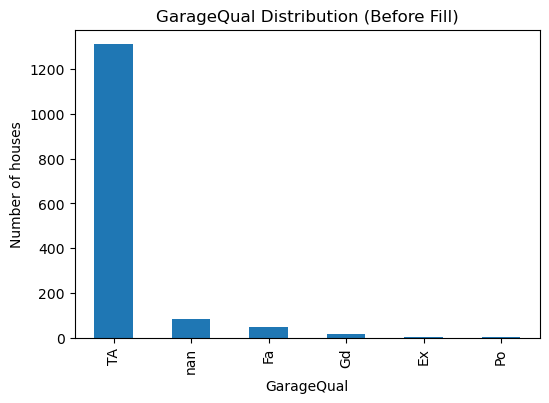

In [5]:
# ==========================================================
# 3) Visualize GarageQual BEFORE filling missing
# ==========================================================

df['GarageQual'].value_counts(dropna=False).sort_values(ascending=False).plot.bar(figsize=(6,4))
plt.xlabel('GarageQual')
plt.ylabel('Number of houses')
plt.title("GarageQual Distribution (Before Fill)")
plt.show()

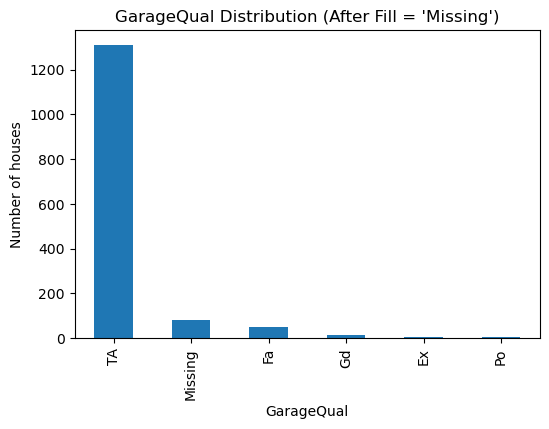

In [6]:
# ==========================================================
# 4) Fill Missing in GarageQual with 'Missing' (Pandas method)
# ==========================================================

df = df.copy()   # safety
df['GarageQual'] = df['GarageQual'].fillna('Missing')

# Visualize AFTER filling missing
df['GarageQual'].value_counts(dropna=False).sort_values(ascending=False).plot.bar(figsize=(6,4))
plt.xlabel('GarageQual')
plt.ylabel('Number of houses')
plt.title("GarageQual Distribution (After Fill = 'Missing')")
plt.show()

In [7]:
# ==========================================================
# 5) Train-Test Split
# ==========================================================

from sklearn.model_selection import train_test_split

X = df.drop(columns=['SalePrice'])
y = df['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("✅ X_train shape:", X_train.shape)
print("✅ X_test shape:", X_test.shape, "\n")


✅ X_train shape: (1168, 2)
✅ X_test shape: (292, 2) 



In [8]:
# ==========================================================
# 6) Sklearn Imputation (Best Practice)
# ==========================================================

from sklearn.impute import SimpleImputer

# constant imputer for categorical columns
imputer = SimpleImputer(strategy='constant', fill_value='Missing')

# Fit ONLY on train, then transform both train & test
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

print("✅ Imputer learned fill values (statistics_):")
print(imputer.statistics_, "\n")

print("✅ X_train_imputed sample (first 5 rows):")
print(X_train_imputed[:5])

✅ Imputer learned fill values (statistics_):
['Missing' 'Missing'] 

✅ X_train_imputed sample (first 5 rows):
[['Missing' 'TA']
 ['TA' 'TA']
 ['Missing' 'Missing']
 ['TA' 'TA']
 ['Gd' 'TA']]


In [9]:
X_train

,FireplaceQu,GarageQual
254,NaN,TA
1066,TA,TA
638,NaN,Missing
799,TA,TA
380,Gd,TA
...,...,...
1095,Gd,TA
1130,TA,TA
1294,NaN,TA
860,Gd,TA
